In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("L8_sales_data.csv")
df.shape

(1030, 14)

In [ ]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   str    
 1   shipping_date    1030 non-null   str    
 2   delivery_date    1025 non-null   str    
 3   region           1030 non-null   str    
 4   category         1030 non-null   str    
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   str    
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   str    
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), str(7)
memory usage: 112.8 KB


In [6]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


In [9]:
df.isnull().sum() # 빈칸개수 sum하면 개수만알려줌 isnull만 하면 모든 셀, T/F로

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

### 일관성 검사

In [10]:
print(df.duplicated().sum()) # 완전히 같은 줄의 수

26


In [11]:
df[df.duplicated(keep=False)].sort_values("order_date").head(4)

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
63,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1029,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1001,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34
128,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34


### 정확성 검사

In [12]:
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print((diff > 1).sum()) # 금액 != 수량 x 단

22


### 시의성 검사

In [1]:
dates = ["order_date", "shipping_date",
    "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
df[dates].agg(["min", "max"])


,order_date,shipping_date,delivery_date
min,2023-01-01,2023-01-04,2023-01-03
max,2025-09-26,2025-09-29,2026-09-14


In [ ]:
today = pd.Timestamp.today()
late = df["shipping_date"] < df["order_date"]
rev = df["delivery_date"] < df["shipping_date"]
print("미래 날짜 :", (df["order_date"] > today).sum())
print("배송일 < 주문일 :", late.sum())
print("도착일 < 배송일 :", rev.sum())

미래 날짜 : 0
배송일 < 주문일 : 0
도착일 < 배송일 : 149


L8-2 시각화

In [20]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

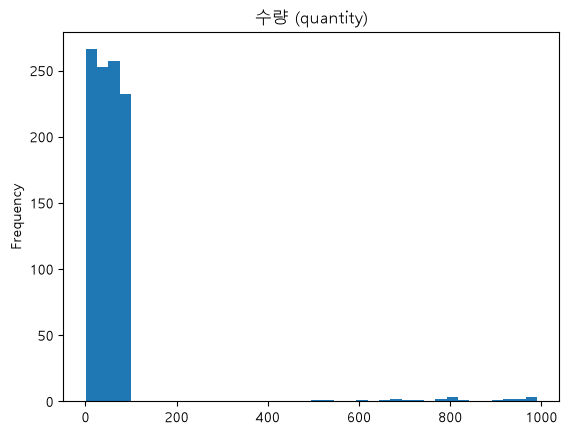

In [21]:
df["quantity"].plot.hist(bins=40, title="수량 (quantity)")
plt.show()

In [22]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0


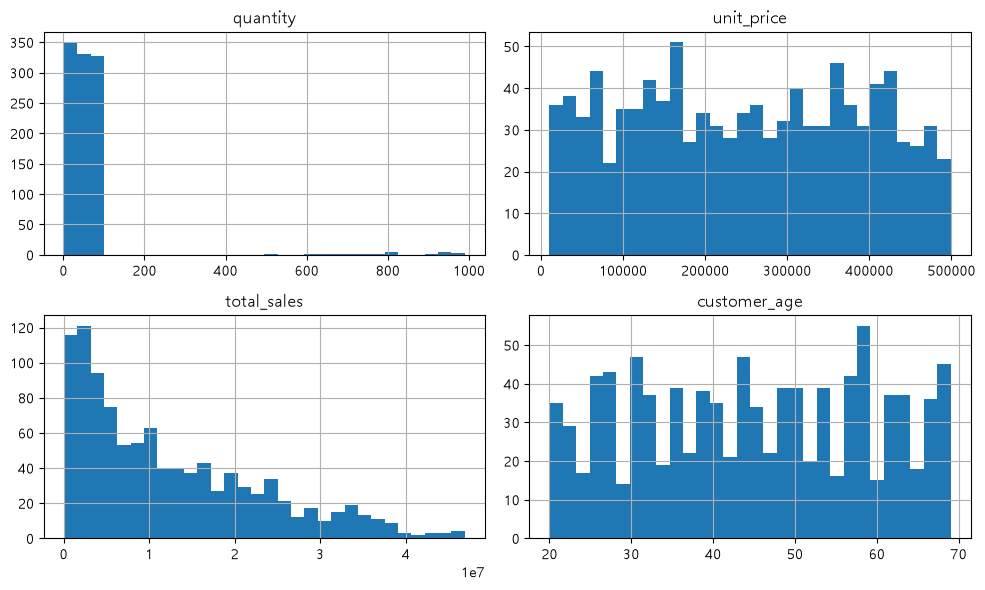

In [23]:
cols = ["quantity", "unit_price",
    "total_sales", "customer_age"]
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

In [24]:
dropped = df.dropna(subset=["customer_age"])
print(len(df), "->", len(dropped))

1030 -> 979


In [25]:
age_mean = df["customer_age"].fillna(df["customer_age"].mean())
print("평균 :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))

평균 : 44.858
중앙값: 44.858
최빈값: 44.858


In [26]:
# 결정 : 세 칸의 빈칸은 그대로 둔다
print(df["customer_age"].count(), "/", len(df))

979 / 1030


In [27]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004
